In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una obra de edificación en el centro de la ciudad, con viviendas en las fachadas vecinas y un hospital enfrente, debe adelantar la entrega **3 semanas**. El cuadro de prelaciones, las duraciones (semanas), las duraciones mínimas, el coste unitario de reducción en jornada diurna (`ucr`, k€ por semana: doblar cuadrillas y medios) y el coste unitario de reducción con **turno de noche** (`ucr_noche`, más barato: los mismos medios, más horas) se adjuntan, junto con la indicación de si la actividad es **ruidosa** (`ruidosa` = 1: demolición, perforación, hormigonado con bomba, maquinaria pesada).

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, cap_duration, ucr, ucr_noche, ruidosa
    ('A'     , '---'      , 5       , 3           , 9  , 5        , 0      ),
    ('B'     , '---'      , 2       , 2           , 0  , 0        , 1      ),
    ('C'     , '---'      , 5       , 2           , 7  , 4        , 0      ),
    ('D'     , 'B'        , 3       , 2           , 9  , 5        , 1      ),
    ('E'     , 'A'        , 4       , 1           , 2  , 1        , 1      ),
    ('F'     , 'C,D,E'    , 6       , 4           , 5  , 3        , 0      ),
    ('G'     , 'F'        , 6       , 6           , 0  , 0        , 0      ),
    ('H'     , 'E'        , 3       , 2           , 1  , 1        , 0      ),
    ('I'     , 'H'        , 5       , 2           , 1  , 1        , 1      ),
], columns=['activity', 'predecessor', 'duration', 'cap_duration', 'ucr', 'ucr_noche', 'ruidosa']).set_index('activity')
datos_enunciado

,predecessor,duration,cap_duration,ucr,ucr_noche,ruidosa
activity,,,,,,
A,---,5,3,9,5,0
B,---,2,2,0,0,1
C,---,5,2,7,4,0
D,B,3,2,9,5,1
E,A,4,1,2,1,1
F,"C,D,E",6,4,5,3,0
G,F,6,6,0,0,0
H,E,3,2,1,1,0
I,H,5,2,1,1,1


La ordenanza municipal de ruido limita los trabajos de obra ruidosos al horario de **8 a 22 h** y sólo admite trabajos ruidosos nocturnos con **autorización expresa y motivada del ayuntamiento**, que en el entorno del hospital no se concede salvo emergencia; el trabajo nocturno no ruidoso (interiores, instalaciones, acabados) es libre. Según la experiencia de la empresa en obras similares, un turno de noche ruidoso sin autorización acaba en denuncia con probabilidad 80%; si hay denuncia, la policía municipal paraliza el turno, la multa es de 12 k€ y la obra pierde 2 semana(s) hasta reorganizarse, con una penalidad de 10 k€ por semana de retraso en la entrega.

> **De: Jefe de obra**
> Turno de noche en todo lo que haga falta, que sale un 40 % más barato que doblar cuadrillas: son sólo 3 semanas y el hospital tiene ventanas dobles. Pedir el permiso tarda seis semanas y no llegamos; si viene la policía, se para esa noche y se sigue al día siguiente.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S12 — Condiciones de la autorización como restricciones del cronograma.** Las condiciones de la declaración de impacto ambiental, de la licencia o de la ordenanza (ventanas biológicas, horarios de trabajo, límites de ruido) son parte del proyecto autorizado: entran en el cronograma como restricciones de fecha u horario de las actividades afectadas, no como riesgos que se aceptan ni como opciones de compresión. Qué actividades quedan afectadas lo decide el calendario, y una ventaja de plazo obtenida incumpliendo la condición no es una opción de la tabla; incumplirla es infracción. *(cf. Ley 21/2013, arts. 41 y 55.3.c); Ley 42/2007, art. 54.5; Ley 37/2003, arts. 6 y 28; PMBOK 8 §3.7.3 (dominio del cronograma: huella y uso de recursos en las decisiones de programación).)*
- **S10 — Condiciones de trabajo en la cadena de ejecución.** El plan no puede apoyarse en condiciones de trabajo que la norma prohíbe: ni en una cadena de subcontratación más larga que la permitida, ni en jornadas al aire libre que ignoren los avisos por calor extremo. Una ventaja de coste o plazo obtenida así no es una opción de la tabla (cf. C7 y C5 de la lección 19). *(cf. Ley 32/2006 de subcontratación en la construcción, arts. 4 y 5; RD 486/1997, disposición adicional única (RDL 4/2023); ICB4, Perspectiva 3 «salud, seguridad y medio ambiente».)*
- **S1 — Jerarquía de respuesta a los impactos (pirámide de sostenibilidad).** Ante un impacto negativo del proyecto las estrategias se ordenan de menos a más deseable: compensar o contrarrestar el daño, restaurarlo, minimizarlo y evitarlo. Compensar cuando se podía minimizar o evitar es quedarse en el escalón más bajo; clasificar una propuesta en su escalón es una pregunta con respuesta única. *(cf. PMBOK 8, principio «integrar la sostenibilidad en todas las áreas del proyecto» (§3.7, figura 3-7).)*
- **Norma o dato de referencia — los ayuntamientos regulan por ordenanza los horarios y límites de las obras ruidosas y pueden autorizar excepciones motivadas; superar los valores límite o incumplir las condiciones de la autorización es infracción grave (601 a 12 000 €) o muy grave si causa daño o riesgo grave para la salud (12 001 a 300 000 €), con posible suspensión de la actividad** *(Ley 37/2003 del Ruido, arts. 6, 28 y 29; RD 1367/2007 (objetivos de calidad acústica y valores límite).)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Obtenga con Ackoff-Sasieni el plan de reducción de 3 semanas más barato usando en cada actividad el menor de los dos costes unitarios (la propuesta del jefe de obra): actividades acortadas en cada paso y coste. ¿Qué actividades ruidosas se harían de noche?  "
pregunta_2 = "2. (A) Repita el algoritmo con el coste unitario legal (turno de noche sólo en las actividades no ruidosas) y compare los dos planes. Calcule el coste esperado de la propuesta con la denuncia (probabilidad por multa y paralización). ¿Cuánto vale el «ahorro» del turno de noche?  "
pregunta_3 = "3. (B) Según el criterio y la norma de referencia, ¿es el turno de noche en actividades ruidosas una opción de la tabla? ¿Cuál es el plan de compresión correcto? ¿En qué escalón de la pirámide queda cada plan?  "
pregunta_4 = "4. (C) ¿Qué propone al jefe de obra y qué comunica al cliente y a los vecinos? Aplique la rúbrica.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Obtenga con Ackoff-Sasieni el plan de reducción de 3 semanas más barato usando en cada actividad el menor de los dos costes unitarios (la propuesta del jefe de obra): actividades acortadas en cada paso y coste. ¿Qué actividades ruidosas se harían de noche?  

2. (A) Repita el algoritmo con el coste unitario legal (turno de noche sólo en las actividades no ruidosas) y compare los dos planes. Calcule el coste esperado de la propuesta con la denuncia (probabilidad por multa y paralización). ¿Cuánto vale el «ahorro» del turno de noche?  

3. (B) Según el criterio y la norma de referencia, ¿es el turno de noche en actividades ruidosas una opción de la tabla? ¿Cuál es el plan de compresión correcto? ¿En qué escalón de la pirámide queda cada plan?  

4. (C) ¿Qué propone al jefe de obra y qué comunica al cliente y a los vecinos? Aplique la rúbrica.  

# Resolución

In [6]:
semanas_pedidas, p_denuncia, multa, paralizacion, penalidad = 3, 0.8, 12, 2, 10
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
datos_proyecto['ucr_propuesta'] = np.minimum(datos_proyecto['ucr'], datos_proyecto['ucr_noche'])
datos_proyecto['ucr_legal'] = np.where(datos_proyecto['ruidosa'] == 1, datos_proyecto['ucr'], datos_proyecto['ucr_propuesta'])
def coste_plan(pasos, columna):
    return float(sum(datos_proyecto.loc[a, columna] for paso in pasos.values() for a in paso))

In [7]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

**Tiempos mínimos (hacia delante)**

- $T_{\mathrm{Inicio}} = 0$
- $T_{A} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{B} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{C} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{D} = 0+2 = 2$ &nbsp; (B)
- $T_{E} = 0+5 = 5$ &nbsp; (A)
- $T_{F} = \max\{0+5,\ 2+3,\ 5+4\} = 9$ &nbsp; (C, D, E)
- $T_{H} = 5+4 = 9$ &nbsp; (E)
- $T_{G} = 9+6 = 15$ &nbsp; (F)
- $T_{I} = 9+3 = 12$ &nbsp; (H)
- $T_{\mathrm{Fin}} = \max\{15+6,\ 12+5\} = 21$ &nbsp; (G, I)

**Tiempos máximos (hacia atrás)**

- $T_{\mathrm{Fin}}^{*} = T_{\mathrm{Fin}} = 21$
- $T_{I}^{*} = 21-5 = 16$ &nbsp; (Fin)
- $T_{G}^{*} = 21-6 = 15$ &nbsp; (Fin)
- $T_{H}^{*} = 16-3 = 13$ &nbsp; (I)
- $T_{F}^{*} = 15-6 = 9$ &nbsp; (G)
- $T_{E}^{*} = \min\{9-4,\ 13-4\} = 5$ &nbsp; (F, H)
- $T_{D}^{*} = 9-3 = 6$ &nbsp; (F)
- $T_{C}^{*} = 9-5 = 4$ &nbsp; (F)
- $T_{B}^{*} = 6-2 = 4$ &nbsp; (D)
- $T_{A}^{*} = 5-5 = 0$ &nbsp; (E)
- $T_{\mathrm{Inicio}}^{*} = \min\{0-0,\ 4-0,\ 4-0\} = 0$ &nbsp; (A, B, C)

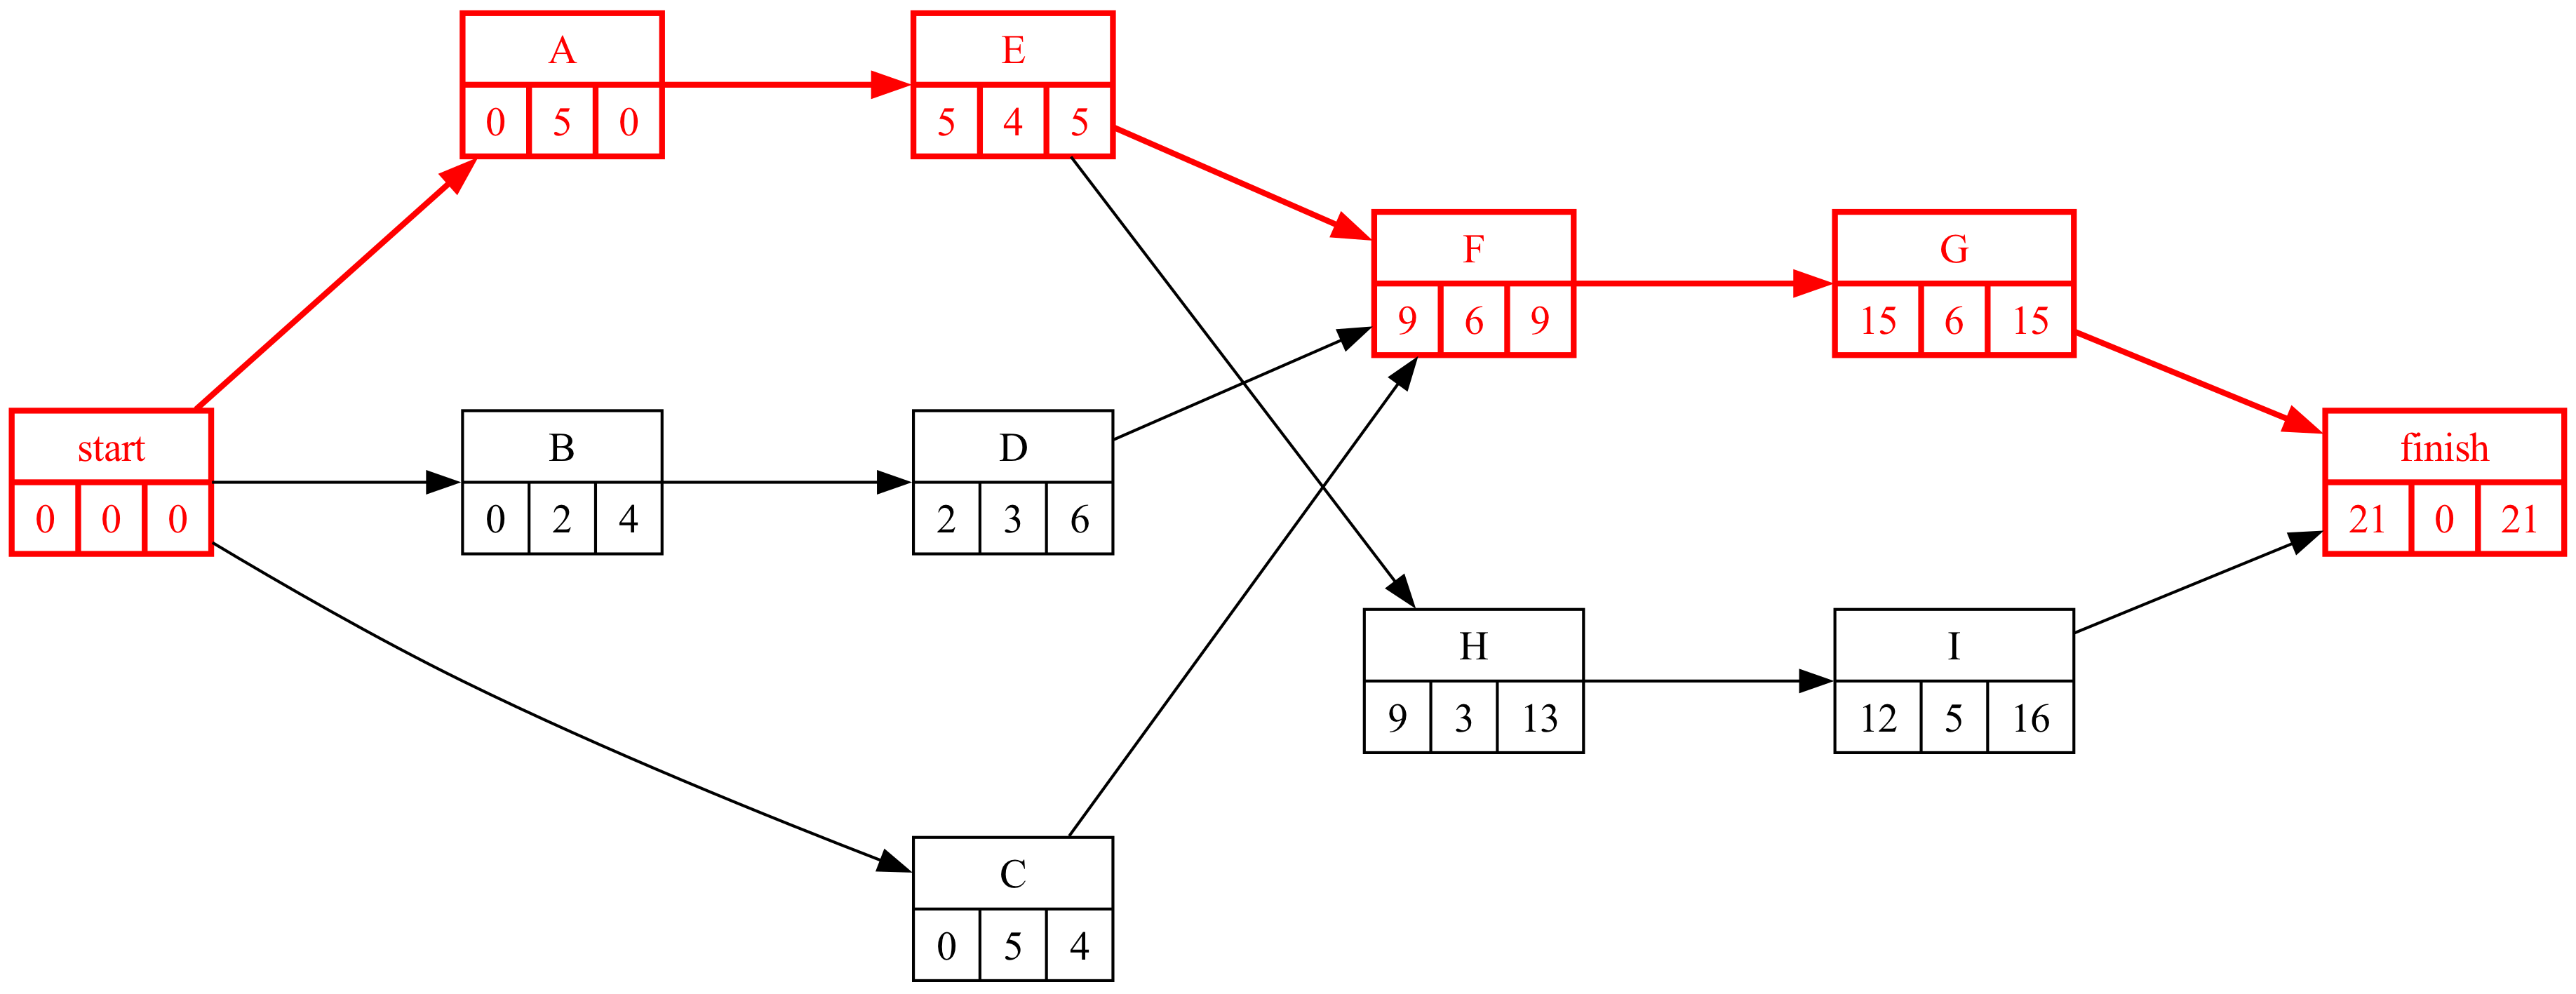

In [8]:
#| fig-cap: "Grafo Roy con el camino crítico"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Obtenga con Ackoff-Sasieni el plan de reducción de 3 semanas más barato usando en cada actividad el menor de los dos costes unitarios (la propuesta del jefe de obra): actividades acortadas en cada paso y coste. ¿Qué actividades ruidosas se harían de noche?  

In [10]:
#| tbl-cap: "Ackoff-Sasieni con el menor coste unitario de cada actividad (propuesta)"
#| label: tbl-ackoffPropuesta
tabla_1, pasos_1, duraciones_1, margen_1 = proyecto.ackoff(durations=datos_proyecto['duration'], min_durations=datos_proyecto['cap_duration'],
                                                         costs=datos_proyecto['ucr_propuesta'], reduction=semanas_pedidas, report=False)
tabla_1

,A,B,C,D,E,F,G,H,I,0,1,2,3
Route_1,5.0,,,,1.0,3.0,0.0,,,21.0,20.0,19.0,18.0
Route_2,5.0,,,,1.0,,,1.0,1.0,17.0,16.0,15.0,14.0
Route_3,,0.0,,5.0,,3.0,0.0,,,17.0,17.0,17.0,17.0
Route_4,,,4.0,,,3.0,0.0,,,17.0,17.0,17.0,17.0
0,2.0,0.0,3.0,1.0,3.0,2.0,0.0,1.0,3.0,,,,
1,2.0,0.0,3.0,1.0,2.0,2.0,0.0,1.0,3.0,,,,
2,2.0,0.0,3.0,1.0,1.0,2.0,0.0,1.0,3.0,,,,
3,2.0,0.0,3.0,1.0,0.0,2.0,0.0,1.0,3.0,,,,


In [11]:
#| tbl-cap: "Opciones consideradas en cada paso (propuesta)"
#| label: tbl-ackoffPaso1
detalle_ackoff(proyecto, datos_proyecto['duration'], datos_proyecto['cap_duration'], datos_proyecto['ucr_propuesta'], pasos_1)

,duración,rutas críticas,opciones (coste),elegida,coste del paso
paso,,,,,
1,21,Route_1,E (1); F (3); A (5),E,1.0
2,20,Route_1,E (1); F (3); A (5),E,1.0
3,19,Route_1,E (1); F (3); A (5),E,1.0


In [12]:
acts_1 = [a for paso in pasos_1.values() for a in paso]
nocturnas_ruidosas = sorted(set(a for a in acts_1 if datos_proyecto.loc[a, 'ruidosa'] == 1 and datos_proyecto.loc[a, 'ucr_noche'] < datos_proyecto.loc[a, 'ucr']))
coste_1 = coste_plan(pasos_1, 'ucr_propuesta')
Markdown('Plan 1 (propuesta): ' + '; '.join('paso ' + str(k + 1) + ': ' + ', '.join(v) for k, v in sorted(pasos_1.items())) + f'''. Coste **{coste_1:.0f} k€**. Actividades ruidosas que se harían de noche: **{', '.join(nocturnas_ruidosas)}**.''')

Plan 1 (propuesta): paso 1: E; paso 2: E; paso 3: E. Coste **3 k€**. Actividades ruidosas que se harían de noche: **E**.

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. (A) Repita el algoritmo con el coste unitario legal (turno de noche sólo en las actividades no ruidosas) y compare los dos planes. Calcule el coste esperado de la propuesta con la denuncia (probabilidad por multa y paralización). ¿Cuánto vale el «ahorro» del turno de noche?  

In [14]:
#| tbl-cap: "Ackoff-Sasieni con el coste unitario legal (noche sólo en las no ruidosas)"
#| label: tbl-ackoffLegal
tabla_2, pasos_2, duraciones_2, margen_2 = proyecto.ackoff(durations=datos_proyecto['duration'], min_durations=datos_proyecto['cap_duration'],
                                                         costs=datos_proyecto['ucr_legal'], reduction=semanas_pedidas, report=False)
tabla_2

,A,B,C,D,E,F,G,H,I,0,1,2,3
Route_1,5.0,,,,2.0,3.0,0.0,,,21.0,20.0,19.0,18.0
Route_2,5.0,,,,2.0,,,1.0,1.0,17.0,16.0,15.0,14.0
Route_3,,0.0,,9.0,,3.0,0.0,,,17.0,17.0,17.0,17.0
Route_4,,,4.0,,,3.0,0.0,,,17.0,17.0,17.0,17.0
0,2.0,0.0,3.0,1.0,3.0,2.0,0.0,1.0,3.0,,,,
1,2.0,0.0,3.0,1.0,2.0,2.0,0.0,1.0,3.0,,,,
2,2.0,0.0,3.0,1.0,1.0,2.0,0.0,1.0,3.0,,,,
3,2.0,0.0,3.0,1.0,0.0,2.0,0.0,1.0,3.0,,,,


In [15]:
#| tbl-cap: "Opciones consideradas en cada paso (legal)"
#| label: tbl-ackoffPaso2
detalle_ackoff(proyecto, datos_proyecto['duration'], datos_proyecto['cap_duration'], datos_proyecto['ucr_legal'], pasos_2)

,duración,rutas críticas,opciones (coste),elegida,coste del paso
paso,,,,,
1,21,Route_1,E (2); F (3); A (5),E,2.0
2,20,Route_1,E (2); F (3); A (5),E,2.0
3,19,Route_1,E (2); F (3); A (5),E,2.0


In [16]:
#| tbl-cap: "Comparación de los dos planes"
#| label: tbl-planes
coste_2 = coste_plan(pasos_2, 'ucr_legal')
esperado_1 = coste_1 + p_denuncia * (multa + paralizacion * penalidad)
comparacion = pd.DataFrame({'plan 1: propuesta (noche en todo)': [coste_1, p_denuncia * multa, p_denuncia * paralizacion * penalidad, esperado_1],
                            'plan 2: legal': [coste_2, 0.0, 0.0, coste_2]},
                           index=['coste de la compresión (k€)', 'multa esperada (k€)', 'paralización esperada (k€)', 'coste esperado (k€)'])
display(comparacion.round(1))
Markdown('Plan 2 (legal): ' + '; '.join('paso ' + str(k + 1) + ': ' + ', '.join(v) for k, v in sorted(pasos_2.items())) + f'''. Coste **{coste_2:.0f} k€**, {coste_2 - coste_1:.0f} k€ más que la propuesta: ese es el «ahorro» del turno de noche. Con la denuncia, el coste esperado de la propuesta es de {esperado_1:.1f} k€''' + (', más que el plan legal: mal negocio además de infracción.' if esperado_1 > coste_2 else ', todavía menor que el plan legal: la respuesta B no depende de esta cuenta.'))

,plan 1: propuesta (noche en todo),plan 2: legal
coste de la compresión (k€),3.0,6.0
multa esperada (k€),9.6,0.0
paralización esperada (k€),16.0,0.0
coste esperado (k€),28.6,6.0


Plan 2 (legal): paso 1: E; paso 2: E; paso 3: E. Coste **6 k€**, 3 k€ más que la propuesta: ese es el «ahorro» del turno de noche. Con la denuncia, el coste esperado de la propuesta es de 28.6 k€, más que el plan legal: mal negocio además de infracción.

## Apartado 3

In [17]:
display(Markdown(pregunta_3))

3. (B) Según el criterio y la norma de referencia, ¿es el turno de noche en actividades ruidosas una opción de la tabla? ¿Cuál es el plan de compresión correcto? ¿En qué escalón de la pirámide queda cada plan?  

**Norma y S12.** El horario de la ordenanza es una condición de la autorización de la obra: el turno de noche en actividades ruidosas junto a viviendas y un hospital, sin autorización expresa, es infracción (Ley 37/2003, arts. 6 y 28) y **no es una opción de la tabla**; sí lo es en las actividades no ruidosas. El plan correcto es el **plan 2**, con el coste unitario legal (6 k€ frente a 3): se excluyen las opciones prohibidas antes de ordenar, no se usan y se paga la multa como un coste. **S10.** El «ahorro» de 3 k€ sale del sueño de los vecinos y de los pacientes del hospital, que no están en la mesa: una ventaja de plazo obtenida incumpliendo la norma no es una opción, y «si viene la policía se para esa noche» describe la infracción, no la evita. **S1.** El plan 1 ni compensa ni minimiza: traslada el impacto a la comunidad; el plan 2 **minimiza** (ruido sólo de día, noche en lo silencioso); **evitar** sería negociar con el cliente las 3 semanas (lección 19, C13) o pedir la autorización con tiempo para lo que de verdad lo necesite.

In [18]:
preguntas_test = [
    ('El turno de noche en actividades ruidosas junto a viviendas y un hospital, sin autorización del ayuntamiento…', ['no es una opción del plan: la ordenanza lo prohíbe y es infracción (Ley 37/2003)', 'es una opción si se compensa a los vecinos', 'es legal si dura menos de un mes', 'es legal si la obra es pública'],
     'S12: condiciones de la autorización como restricciones del plan.'),
    ('Al aplicar Ackoff-Sasieni cuando algunas opciones de compresión están prohibidas para ciertas actividades…', ['se excluyen esas opciones (coste unitario legal) antes de ordenar', 'se usan y se añade la multa como coste', 'se reduce el número de semanas pedidas', 'no cambia nada'],
     'El algoritmo ordena las opciones admisibles; la multa no convierte en admisible lo prohibido.'),
    ('Trasladar el ruido nocturno a los vecinos para abaratar la compresión es, en la pirámide de la sostenibilidad…', ['trasladar el impacto: ni siquiera compensa', 'minimizar', 'restaurar', 'evitar'],
     'S1: la pirámide empieza en compensar; la propuesta está por debajo.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — turno de noche')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Sostenibilidad 20 — turno de noche

::Sostenibilidad 20 — turno de noche P1::El turno de noche en actividades ruidosas junto a viviendas y un hospital, sin autorización del ayuntamiento… {=no es una opción del plan: la ordenanza lo prohíbe y es infracción (Ley 37/2003) ~es una opción si se compensa a los vecinos ~es legal si dura menos de un mes ~es legal si la obra es pública ####S12: condiciones de la autorización como restricciones del plan.}

::Sostenibilidad 20 — turno de noche P2::Al aplicar Ackoff-Sasieni cuando algunas opciones de compresión están prohibidas para ciertas actividades… {~no cambia nada =se excluyen esas opciones (coste unitario legal) antes de ordenar ~se reduce el número de semanas pedidas ~se usan y se añade la multa como coste ####El algoritmo ordena las opciones admisibles; la multa no convierte en admisible lo prohibido.}

::Sostenibilidad 20 — turno de noche P3::Trasladar el ruido nocturno a los vecinos para abaratar la compresión es, en la pirám

## Apartado 4

In [19]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al jefe de obra y qué comunica al cliente y a los vecinos? Aplique la rúbrica.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al jefe de obra: el plan 2 con sus pasos y su coste, y la petición de autorización para lo que sí pueda justificarse (un hormigonado continuo, por ejemplo) presentada hoy, no «cuando haga falta». Al cliente: el precio de cada semana con el plan legal (2.0 k€ por semana de media) y la alternativa de adelantar menos. A los vecinos y al hospital: el calendario de los trabajos ruidosos y el horario, antes de empezar. Prueba de publicidad: ¿explicaría al gerente del hospital que el martillo de las 3 de la mañana ahorraba 3 k€?